# **K-means**

**K-means (k-medias)** es un algoritmo de aprendizaje automático no supervisado que divide un conjunto de datos en k grupos o clústeres basándose en la similitud de sus características.

Su principal limitación es que el usuario debe definir el valor de k inicialmente.

Este algoritmo se usa cuando tenemos datos sin etiquetas. Por ejemplo, medidas de flores (largo de pétalo, ancho de pétalo) pero no se sabe qué tipos de flores son. Se quiere descubrir cuántos tipos de flores hay.

En realidad, sí se conocen las tres especies, que luego usaremos para comparar el resultado obtenido: Iris **setosa**, Iris **versicolor** e Iris **virginica**.

Esto es aprendizaje no supervisado: no hay una respuesta correcta.

In [1]:
from sklearn.datasets import load_iris

iris = load_iris()
print(type(iris))

<class 'sklearn.utils._bunch.Bunch'>


In [2]:
iris.feature_names
iris.target
#iris.target_names
#iris.DESCR

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [3]:
datos = iris.data
print(type(datos))
datos

<class 'numpy.ndarray'>


array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [4]:
# operaciones
primera_flor = datos[0]
primera_flor
un_valor = datos[5, 2]
un_valor
rango10a15 = datos[10:15]
rango10a15
rango0a3 = datos[:3]
rango0a3

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2]])

In [5]:
# se dispone de 150 datos, para cada uno 4 medidas
datos.shape

(150, 4)

In [6]:
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 3
# =====================================

# se configura el modelo
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
# se entrena el modelo
modelo.fit(datos)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [7]:
print(modelo.labels_)          # etiqueta de cluster (0, 1, 2...) de cada muestra
print(modelo.cluster_centers_) # coordenadas de los K centroides (shape: K × n_features)
print(modelo.inertia_)         # suma de distancias² (cómo de "compactos" son los clusters)
print(modelo.n_iter_)          # iteraciones que necesitó para converger

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.428      1.462      0.246     ]
 [6.85       3.07368421 5.74210526 2.07105263]]
78.851441426146
4


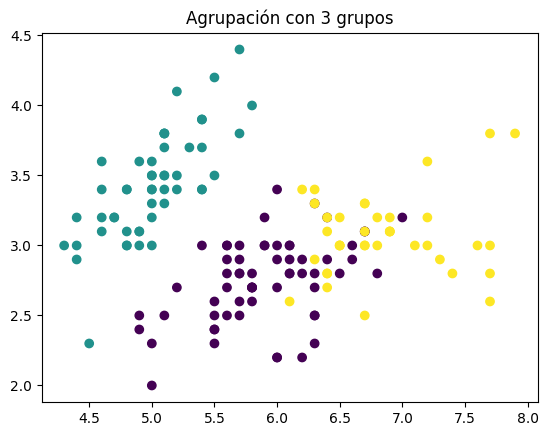

In [8]:
import matplotlib.pyplot as plt

plt.scatter(datos[:, 0], datos[:, 1], c=modelo.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters} grupos")
plt.show()

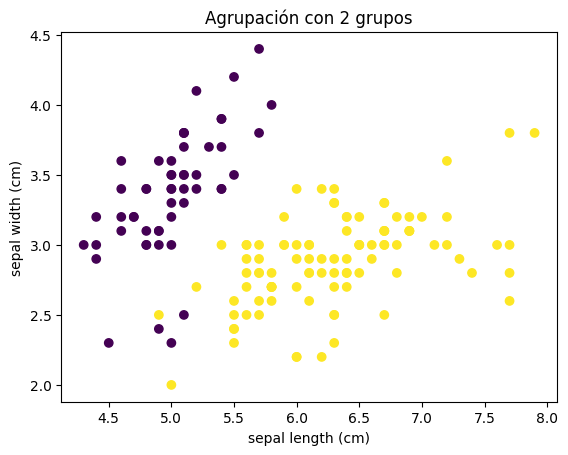

Inercia con 2 grupos: 152.3479517603579


In [9]:
# Prueba el algoritmo con 2 grupos
modelo_2 = KMeans(n_clusters=2, random_state=0, n_init=10)
modelo_2.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_2.labels_, cmap="viridis")
plt.title("Agrupación con 2 grupos")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.show()

print("Inercia con 2 grupos:", modelo_2.inertia_)

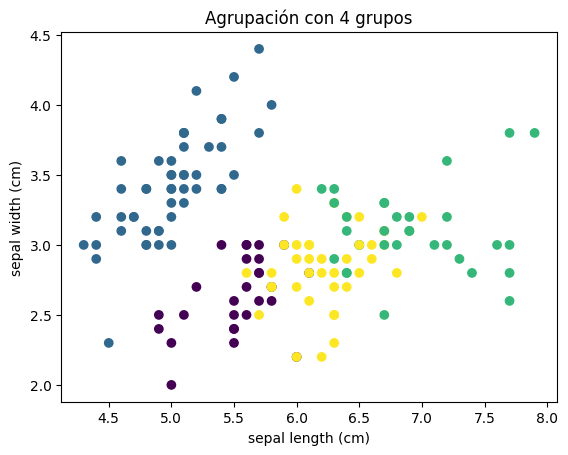

Inercia con 4 grupos: 57.22847321428572


In [10]:
# Prueba el algoritmo con 4 grupos
modelo_4 = KMeans(n_clusters=4, random_state=0, n_init=10)
modelo_4.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_4.labels_, cmap="viridis")
plt.title("Agrupación con 4 grupos")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.show()

print("Inercia con 4 grupos:", modelo_4.inertia_)

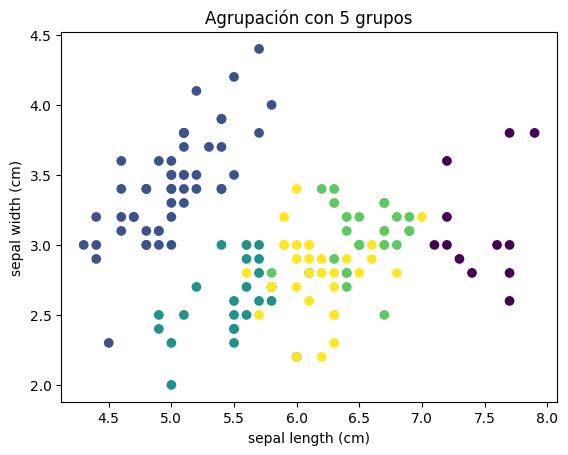

Inercia con 5 grupos: 46.446182051282065


In [11]:
# Prueba el algoritmo con 5 grupos
modelo_5 = KMeans(n_clusters=5, random_state=0, n_init=10)
modelo_5.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_5.labels_, cmap="viridis")
plt.title("Agrupación con 5 grupos")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.show()

print("Inercia con 5 grupos:", modelo_5.inertia_)

**K-Means sirve para datos sin etiquetar, ¿qué datos reales llegan sin etiquetar en el mundo profesional?**

En el mundo profesional llegan sin etiquetar muchos datos que se generan de forma automática. Algunos ejemplos son:

- **Clientes de una tienda o plataforma:** compras, frecuencia de visita y gasto, para descubrir perfiles de clientes.
- **Registros de navegación web:** páginas visitadas, tiempo de permanencia y clics, para encontrar patrones de comportamiento.
- **Datos de sensores industriales:** temperatura, vibración o consumo eléctrico, para detectar comportamientos similares o anomalías.
- **Documentos y comentarios:** textos que todavía no han sido clasificados por temática.

K-Means puede agrupar estos datos según sus características sin necesitar etiquetas previas. Después, una persona experta puede interpretar qué representa cada grupo.

El tipo de dato **numpy.ndarray** es un array de **NumPy**, para extraer fragmentos de datos debes usar coordenadas dentro de corchetes con la estructura:

datos[filas, columnas]

Los datos se pueden guardar en un array estructurado como si fuera una tabla de Excel con nombres en las columnas, lo ideal es transformarlo en un **DataFrame de Pandas**.


In [12]:
import pandas as pd

tabla = pd.DataFrame(datos, columns=iris.feature_names)
print(tabla.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [13]:
# también se puede importar los datos directamente,
# pero así no se dispone de los nombres de las columnas
tabla2 = pd.DataFrame(datos)
print(tabla2.head())

     0    1    2    3
0  5.1  3.5  1.4  0.2
1  4.9  3.0  1.4  0.2
2  4.7  3.2  1.3  0.2
3  4.6  3.1  1.5  0.2
4  5.0  3.6  1.4  0.2


In [14]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [15]:
tabla.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [16]:
tabla['petal length (cm)']

0      1.4
1      1.4
2      1.3
3      1.5
4      1.4
      ... 
145    5.2
146    5.0
147    5.2
148    5.4
149    5.1
Name: petal length (cm), Length: 150, dtype: float64

In [17]:
flores_grandes = tabla[tabla['petal length (cm)'] > 5]
flores_grandes

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
83,6.0,2.7,5.1,1.6
100,6.3,3.3,6.0,2.5
101,5.8,2.7,5.1,1.9
102,7.1,3.0,5.9,2.1
103,6.3,2.9,5.6,1.8
104,6.5,3.0,5.8,2.2
105,7.6,3.0,6.6,2.1
107,7.3,2.9,6.3,1.8
108,6.7,2.5,5.8,1.8
109,7.2,3.6,6.1,2.5


In [18]:
# aquí se agregan tres columnas que representan el código de la especie,
# el nombre de la especie a la tabla y el código del cluster asignado
tabla['species'] = iris.target
tabla['species_name'] = tabla['species'].map(lambda x: iris.target_names[x])
tabla['cluster'] = modelo.labels_

In [19]:
tabla

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name,cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica,2
146,6.3,2.5,5.0,1.9,2,virginica,0
147,6.5,3.0,5.2,2.0,2,virginica,2
148,6.2,3.4,5.4,2.3,2,virginica,2


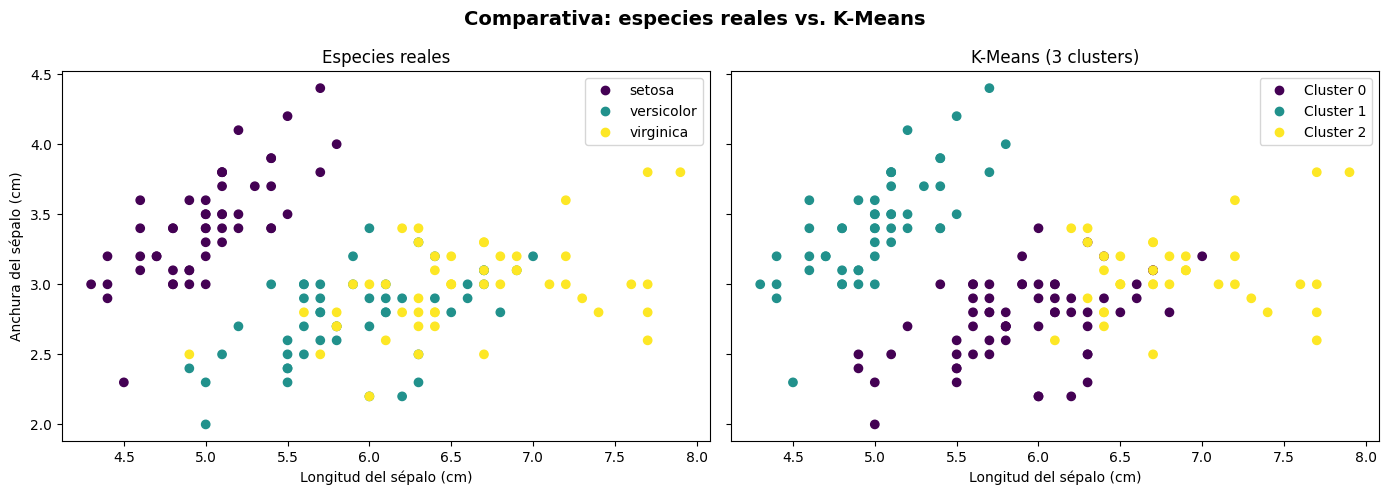

In [20]:
# Para comparar el resultado con las especies reales (el modelo principal usa 3 clusters)
n_clusters = 3

# Creamos una figura con 2 gráficos enfrentados (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

scatter1 = ax1.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['species'],
    cmap='viridis'
)
ax1.set_title("Especies reales")
ax1.set_xlabel("Longitud del sépalo (cm)")
ax1.set_ylabel("Anchura del sépalo (cm)")
ax1.legend(handles=scatter1.legend_elements()[0], labels=list(iris.target_names))

scatter2 = ax2.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['cluster'],
    cmap='viridis'
)
ax2.set_title(f"K-Means ({n_clusters} clusters)")
ax2.set_xlabel("Longitud del sépalo (cm)")
ax2.legend(handles=scatter2.legend_elements()[0], labels=[f'Cluster {i}' for i in range(n_clusters)])

plt.suptitle("Comparativa: especies reales vs. K-Means", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [21]:
# para comparar el resultado con las especies reales
print(modelo.labels_)
print(iris.target)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


Implementa una comparación entre los resultados obtenidos y los resultados reales.

In [22]:
# Comparación entre los clusters obtenidos y las especies reales

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import confusion_matrix
from scipy.optimize import linear_sum_assignment
import numpy as np

# Tabla cruzada: muestra cuántas flores de cada especie han quedado en cada cluster.
# Las etiquetas de los clusters (0, 1, 2) no tienen por qué coincidir con las especies (0, 1, 2).
comparacion = pd.crosstab(
    pd.Series(iris.target, name="Especie real"),
    pd.Series(modelo.labels_, name="Cluster asignado")
)
comparacion.index = iris.target_names
display(comparacion)

# Métricas que comparan agrupaciones sin exigir que coincidan los números de las etiquetas.
ari = adjusted_rand_score(iris.target, modelo.labels_)
nmi = normalized_mutual_info_score(iris.target, modelo.labels_)

print(f"Adjusted Rand Index (ARI): {ari:.3f}")
print(f"Normalized Mutual Information (NMI): {nmi:.3f}")

# Para calcular una exactitud orientativa, emparejamos las etiquetas de cluster
# con las especies mediante la asignación óptima.
matriz = confusion_matrix(iris.target, modelo.labels_)
filas, columnas = linear_sum_assignment(-matriz)
aciertos = matriz[filas, columnas].sum()
exactitud = aciertos / len(iris.target)
print(f"Exactitud tras emparejar las etiquetas: {exactitud:.3f}")

print("\nInterpretación:")
print("- ARI y NMI valen 1 si las dos agrupaciones coinciden perfectamente.")
print("- Un valor cercano a 0 indica que la coincidencia es similar a la esperada por azar.")
print("- K-Means no conoce las especies: agrupa por distancias y las etiquetas de cluster son arbitrarias.")
print("- La exactitud anterior depende del emparejamiento óptimo de clusters y especies.")

Cluster asignado,0,1,2
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


Adjusted Rand Index (ARI): 0.730
Normalized Mutual Information (NMI): 0.758
Exactitud tras emparejar las etiquetas: 0.893

Interpretación:
- ARI y NMI valen 1 si las dos agrupaciones coinciden perfectamente.
- Un valor cercano a 0 indica que la coincidencia es similar a la esperada por azar.
- K-Means no conoce las especies: agrupa por distancias y las etiquetas de cluster son arbitrarias.
- La exactitud anterior depende del emparejamiento óptimo de clusters y especies.
